# Project analysis: what we tried, what worked, what did not

Technion 097215 NLP final project (Track 1), Dima Bshara. Text-tabular prediction on the 20 text datasets of MulTaBench
(AUROC for classification, R² for regression), compared with the official leaderboard.

This notebook collects **every result of the project (P1–P6)** in one place, in plain English, and produces the
figures and tables for the paper. It reads only small files committed to the repo, so it runs on a laptop in seconds:

| file | what it holds | written by |
|---|---|---|
| `reports/phase0/*.csv` | the leaderboard's own numbers, before we ran anything | `scripts/phase0` notebook (E2) |
| `reports/pilot/*` | pilot results: engine check, leakage, A/A control, variant pilots | `scripts/pilot_report.py` (E8–E16) |
| `reports/full/c1_report.json` | claim C1 (full run of our first method) | `scripts/full_report.py` (E17) |
| `reports/cte/cte_report.json` | claim C2 (CTE, our final method) | `scripts/cte_report.py` (E24) |
| `reports/tables/fold_scores.csv` | one row per (method, learner, dataset, fold) of the two full runs | `scripts/collect_fold_scores.py` |
| `reports/p6/p6_report.json` | claim C3 (P6), **once P6 has run** | `scripts/p6_report.py` |

Every number is traceable to an entry in `PROGRESS.md` (E-numbers in brackets). Claims are reported **exactly as
pre-registered**: a claim either passed its pre-registered test or it did not.

**Words used below**
- *Joint Frozen*: the leaderboard baseline that embeds each text column with a frozen e5-small-v2 and keeps 30 PCA
  components. *Joint TAR*: the same, but the encoder is first fine-tuned on the training labels (LoRA). TAR is the bar we
  must beat.
- *Fold*: one of 5 train/test splits. Scores are averaged over the 5 folds per dataset, then the 20 datasets are compared.
- *Wilcoxon test*: a test on the 20 per-dataset differences that asks "is the typical difference above zero?". It is
  robust to a few large values. *p < 0.05* is our pre-registered bar.
- *OOF (out-of-fold) / cross-fitted*: a prediction for a training row made by a model that never saw that row's label.

In [1]:
import json
from os.path import exists, join

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = ".." if exists("../reports") else "."
R = lambda *p: join(ROOT, "reports", *p)
FIG = R("figures")
import os; os.makedirs(FIG, exist_ok=True)

# Colours: the validated reference palette of our dataviz guide (light mode, print). At most 3 categorical colours per
# chart (the 3 slots validated all-pairs); gains/losses use the blue <-> red diverging pair with a grey midpoint.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
POS, NEG, MID = "#2a78d6", "#e34948", "#b9b8b2"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "figure.dpi": 110,
})

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(join(FIG, f"{name}.{ext}"), bbox_inches="tight", dpi=200)

def short(ds):
    return (ds.replace("BIN_TEXT_", "").replace("MUL_TEXT_", "").replace("REG_TEXT_", "").replace("_", " ").title()
              .replace("Scimagojr", "SCImago").replace("Us ", "US "))

def fmt_p(p):
    return "n/a" if p is None else (f"{p:.1e}" if p < 1e-3 else f"{p:.3g}")

def diverging_bars(ax, labels, values, highlight=None, xlabel="", note_fmt="{:+.3f}"):
    order = np.argsort(values)
    y = np.arange(len(values))
    vals = np.asarray(values)[order]
    labs = [labels[i] for i in order]
    colors = [MID if abs(v) < 5e-4 else POS if v > 0 else NEG for v in vals]
    ax.barh(y, vals, color=colors, height=0.62, edgecolor=SURFACE, linewidth=1)
    ax.axvline(0, color=INK2, linewidth=0.8)
    ax.set_yticks(y, [f"{l} *" if highlight and l in highlight else l for l in labs])
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    span = np.abs(vals).max()
    for yi, v in zip(y, vals):
        ax.text(v + (0.012 * span if v >= 0 else -0.012 * span), yi, "±0.000" if abs(v) < 5e-4 else note_fmt.format(v), va="center",
                ha="left" if v >= 0 else "right", fontsize=7, color=INK2)
    ax.set_xlim(vals.min() - 0.25 * span, vals.max() + 0.25 * span)

fold = pd.read_csv(R("tables", "fold_scores.csv"))
c1 = json.load(open(R("full", "c1_report.json")))
c2 = json.load(open(R("cte", "cte_report.json")))
print(f"fold-level rows: {len(fold)}; methods: {sorted(fold.method.unique())}")

fold-level rows: 1524; methods: ['catboost_native_text', 'cte', 'cte_lex', 'cte_lex_insample', 'cte_nb', 'cte_nbr', 'cte_num', 'cte_probe', 'cte_residual', 'frozen0', 'frozen_xfit_pred', 'tar_repro', 'tf_num_lsa']


## 1. The gap we try to close (Phase 0, E2)

Before running anything we looked at the leaderboard's own numbers. Fine-tuning the encoder (TAR) beats the frozen
encoder (Frozen) on every dataset with CatBoost, but usually by a little (+0.004 to +0.024), with two large
exceptions: Jigsaw (toxic comments, +0.108) and Video Games (+0.094). A method that wants to "significantly beat TAR" has to win across many
datasets, not just on one.

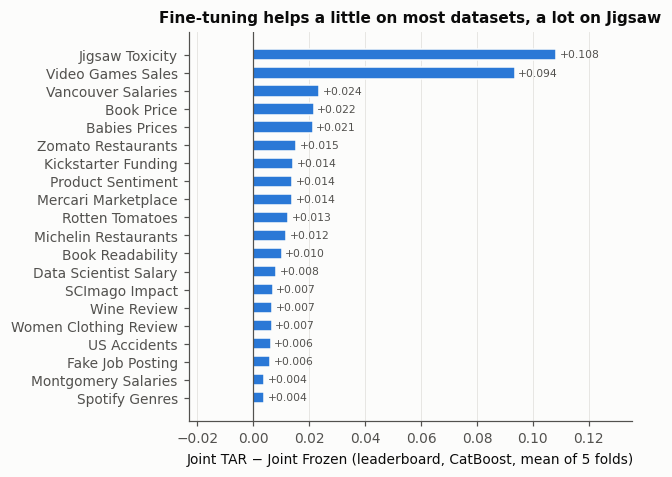

median gain +0.0121; datasets where TAR > Frozen: 20/20


In [2]:
g = pd.read_csv(R("phase0", "gain_table.csv"))
g = g[g.learner == "CatBoost"].copy()
g["name"] = g.dataset.map(short)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
diverging_bars(ax, list(g.name), list(g.gain_mean), xlabel="Joint TAR − Joint Frozen (leaderboard, CatBoost, mean of 5 folds)")
ax.set_title("Fine-tuning helps a little on most datasets, a lot on Jigsaw")
save(fig, "fig0_tar_minus_frozen"); plt.show()
print(f"median gain {g.gain_mean.median():+.4f}; datasets where TAR > Frozen: {(g.gain_mean > 0).sum()}/{len(g)}")

## 2. P1 — Reproducing TAR ourselves (E4–E9)

We rebuilt the TAR fine-tuning in a faster engine (11.9× per epoch on a T4, E6) and checked it against the
leaderboard on a pilot of 6 datasets × 3 folds.

- **Engine bias** (our TAR − leaderboard TAR): small and not significant, so our environment is not systematically
  better or worse than theirs.
- **Leakage gap**: TAR's prediction head is clearly better on the rows the encoder was fine-tuned on than on unseen
  test rows. Those training-row embeddings are "in-sample", which is the weakness every later idea tries to fix.
- **A/A control** (same method, seed 43 vs seed 42): the noise between two seeds is about ±0.006 per dataset. Any
  effect smaller than that is not distinguishable from noise on a 6-dataset pilot.

In [3]:
eb = json.load(open(R("pilot", "engine_bias_overall.json")))
aa = json.load(open(R("pilot", "aa_control.json")))
lk = pd.read_csv(R("pilot", "leakage.csv"))
display(Markdown(f"""
| check | result |
|---|---|
| engine bias (our TAR − leaderboard TAR), 18 jobs | {eb['mean_diff']:+.4f}, Wilcoxon p = {fmt_p(eb['wilcoxon_jobs']['p_value'])}, {eb['n_negative']}/18 below |
| leakage gap (head quality on E5's own training rows − on test), 6 datasets | {lk.gap.mean():+.4f} on average, positive on {(lk.gap > 0).sum()}/{len(lk)} datasets |
| A/A control (seed 43 − seed 42) | mean {aa['mean_gain']:+.4f}, mean absolute {aa['mean_abs_gain']:.4f}, max {aa['max_abs_gain']:.4f} |
"""))
lk.assign(dataset=lk.dataset.map(short))[["dataset", "e5_train", "test", "gap"]].round(4)


| check | result |
|---|---|
| engine bias (our TAR − leaderboard TAR), 18 jobs | -0.0036, Wilcoxon p = 0.154, 12/18 below |
| leakage gap (head quality on E5's own training rows − on test), 6 datasets | +0.0311 on average, positive on 5/6 datasets |
| A/A control (seed 43 − seed 42) | mean +0.0028, mean absolute 0.0061, max 0.0105 |


,dataset,e5_train,test,gap
0,Data Scientist Salary,0.8359,0.8043,0.0316
1,Product Sentiment,0.8452,0.8110,0.0342
2,Babies Prices,0.4654,0.4664,-0.0010
3,Book Price,0.4099,0.3573,0.0527
4,Book Readability,0.5775,0.5492,0.0282
5,Montgomery Salaries,0.5819,0.5408,0.0411


## 3. P2 and P3 — Variant pilots (E13, E15–E16)

We tried five ways to change *how* TAR is fine-tuned (P2: offset by a structured model, prefixes, row context) and
four ways to *stack* TAR's predictions as features (P3). Each was compared with our TAR on the 6-dataset pilot
against a pre-registered advance rule (mean gain ≥ +0.005 and wins on ≥ 4/6 datasets). **None passed.** The best
was the cross-fitted prediction of a frozen encoder (`frozen_xfit_pred`, +0.0040), which became the method for the
first full run (P4).

In [4]:
rows = []
for v, phase in [("offset", "P2"), ("prefix", "P2"), ("prefix_offset", "P2"), ("context", "P2"), ("context_offset", "P2"),
                 ("insample_pred", "P3"), ("xfit_pred", "P3"), ("frozen_xfit_pred", "P3"), ("xfit_offset_pred", "P3")]:
    p = R("pilot", f"advance_{v}.json")
    if exists(p):
        a = json.load(open(p))
        rows.append({"phase": phase, "variant": v, "mean gain vs our TAR": round(a["mean_gain"], 4),
                     "wins (of 6)": a["wins"], "passes the advance rule": a["passes"]})
pilot = pd.DataFrame(rows)
pilot

,phase,variant,mean gain vs our TAR,wins (of 6),passes the advance rule
0,P2,offset,0.0031,4,False
1,P2,prefix,-0.0065,3,False
2,P2,prefix_offset,-0.0038,1,False
3,P2,context,-0.0222,1,False
4,P2,context_offset,-0.0224,1,False
5,P3,insample_pred,0.0028,5,False
6,P3,xfit_pred,0.0033,5,False
7,P3,frozen_xfit_pred,0.0040,4,False
8,P3,xfit_offset_pred,0.0035,6,False


## 4. P4 — Claim C1: the first full run (E17)

**Claim C1** (pre-registered): CatBoost with cross-fitted frozen-encoder predictions beats leaderboard Joint TAR over
20 datasets (two-sided Wilcoxon, p < 0.05, positive mean). **It did not pass**: the mean difference was slightly
negative, and Video Games lost badly. What we learned: the same e5 encoder read through the same 30 PCA components
gives the learner little that TAR does not already give. Our next method had to bring **a different kind of text
signal**, not another view of the same embeddings.

**C1 (CatBoost, 20 datasets):** mean -0.0025, CI [-0.0089, +0.0017], p = 0.409, wins 7/20 → **does not pass**

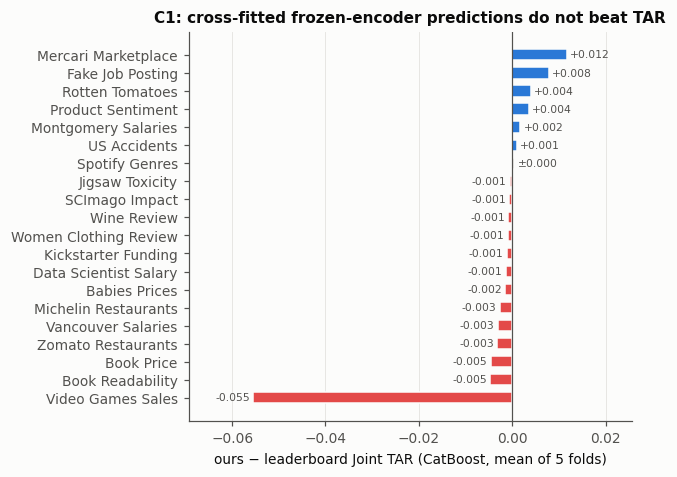

In [5]:
p = c1["primary"]["catboost"]
display(Markdown(f"**C1 (CatBoost, 20 datasets):** mean {p['mean_diff']:+.4f}, CI [{p['ci95'][0]:+.4f}, {p['ci95'][1]:+.4f}], "
                 f"p = {fmt_p(p['p_value'])}, wins {p['wins']}/{p['n']} → **{'PASS' if p['passes'] else 'does not pass'}**"))
d = pd.Series(p["per_dataset"])
fig, ax = plt.subplots(figsize=(5.2, 4.6))
diverging_bars(ax, [short(k) for k in d.index], list(d.values), xlabel="ours − leaderboard Joint TAR (CatBoost, mean of 5 folds)")
ax.set_title("C1: cross-fitted frozen-encoder predictions do not beat TAR")
save(fig, "fig1_c1_per_dataset"); plt.show()

## 5. P5 — Claim C2: Cross-fitted Text Experts (CTE), the base of our final method (E20–E24)

**The idea.** Keep the frozen encoder (no fine-tuning at all), and give the tabular learner a few extra columns per
dataset that already *answer the question*: for each row, what do cheap text models predict for its label?

- a **lexical expert**: TF-IDF (words + character n-grams) of all text columns + a ridge regression;
- a **neighbour expert**: the labels of the 20 most similar training rows in the frozen embedding space;
- **numeracy features**: numbers, years, prices, lengths found in the text (no labels needed).

Every expert prediction for a training row is **out-of-fold** (5-fold cross-fitting): the row's own label never
touches the prediction made for it. Validation and test rows get predictions from experts fitted on all training rows.

**Claim C2** (pre-registered before any full-run result, then two dated amendments for speed and the multiclass
column budget, also before the run): CatBoost CTE vs leaderboard Joint TAR over 20 datasets, two-sided Wilcoxon,
pass = p < 0.05 and positive mean.

In [6]:
lab = {"C2": "C2 — primary, all 20 datasets", "C2_heldout13": "held-out 13 (pre-registered, amendment 2) — secondary",
       "C2_strict11": "strict 11 (pre-registered, amendment 2) — secondary", "C2_16": "16 (pre-registered) — secondary",
       "C2_14": "14 (pre-registered) — secondary", "vs_joint_frozen": "vs Joint Frozen (context, weaker baseline)"}
rows = []
for k, name in lab.items():
    c = c2[k]
    rows.append({"comparison (CatBoost CTE vs …)": name, "n": c["n"], "mean diff": round(c["mean_diff"], 4),
                 "95% CI": f"[{c['ci95'][0]:+.4f}, {c['ci95'][1]:+.4f}]", "p": fmt_p(c["p_value"]), "wins": c["wins"],
                 "passes": {True: "PASS", False: "no"}.get(c.get("passes"), "—")})
s = c2["secondary"]["lgbm"]
rows.append({"comparison (CatBoost CTE vs …)": "LightGBM CTE vs Joint TAR (pre-registered secondary, Holm)", "n": s["n"],
             "mean diff": round(s["mean_diff"], 4), "95% CI": f"[{s['ci95'][0]:+.4f}, {s['ci95'][1]:+.4f}]",
             "p": f"{fmt_p(s['p_value'])} (Holm {fmt_p(s['p_holm'])})", "wins": s["wins"],
             "passes": "PASS" if s["p_holm"] < 0.05 and s["mean_diff"] > 0 else "no"})
table_c2 = pd.DataFrame(rows)
table_c2.to_csv(R("tables", "table_c2.csv"), index=False)
table_c2

,comparison (CatBoost CTE vs …),n,mean diff,95% CI,p,wins,passes
0,"C2 — primary, all 20 datasets",20,0.0106,"[+0.0028, +0.0193]",0.0583,11,no
1,"held-out 13 (pre-registered, amendment 2) — se...",13,0.0173,"[+0.0073, +0.0282]",0.0105,9,PASS
2,"strict 11 (pre-registered, amendment 2) — seco...",11,0.0139,"[+0.0035, +0.0260]",0.042,7,PASS
3,16 (pre-registered) — secondary,16,0.0125,"[+0.0029, +0.0230]",0.0654,9,no
4,14 (pre-registered) — secondary,14,0.0092,"[-0.0002, +0.0205]",0.217,7,no
5,"vs Joint Frozen (context, weaker baseline)",20,0.0310,"[+0.0201, +0.0428]",1.9e-06,20,—
6,LightGBM CTE vs Joint TAR (pre-registered seco...,20,0.0152,"[+0.0047, +0.0263]",0.0215 (Holm 0.0215),14,PASS


**Reading the table.** The primary claim **C2 does not pass** (p = 0.058; the pre-registered bar is 0.05), even
though the average gain is positive and its bootstrap confidence interval excludes zero. On the 13 datasets we never
looked at before the run (held-out 13), the gain is larger and significant, and with LightGBM as the learner the
pre-registered secondary test passes. These secondary results must be reported as secondary, never as the claim.

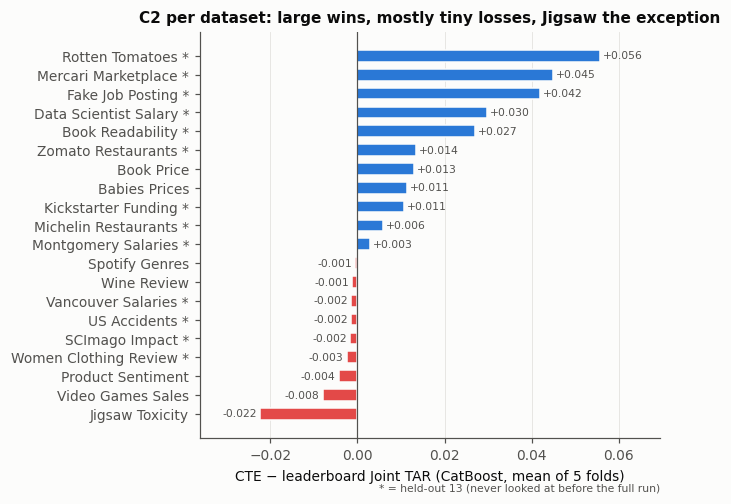

folds won per dataset (of 5): {'Jigsaw Toxicity': 0, 'Wine Review': 0, 'Women Clothing Review': 1, 'US Accidents': 2, 'Spotify Genres': 2, 'Product Sentiment': 2, 'SCImago Impact': 2, 'Babies Prices': 3, 'Vancouver Salaries': 3, 'Video Games Sales': 3, 'Montgomery Salaries': 4, 'Book Price': 4, 'Michelin Restaurants': 5, 'Fake Job Posting': 5, 'Kickstarter Funding': 5, 'Data Scientist Salary': 5, 'Rotten Tomatoes': 5, 'Mercari Marketplace': 5, 'Book Readability': 5, 'Zomato Restaurants': 5}


In [7]:
cte = fold[(fold.method == "cte") & (fold.learner == "catboost")]
per = (cte.assign(diff=cte.score - cte.lb_joint_tar).groupby("dataset")["diff"].mean())
assert np.allclose(per.sort_index().values, pd.Series(c2["C2"]["per_dataset"]).sort_index().values, atol=1e-4)
held = set(per.index) - set(c2["C2"]["excluded_datasets"] or []) - set(c2["C2_heldout13"]["excluded_datasets"])
heldout = {short(k) for k in c2["C2_heldout13"]["per_dataset"]}
fig, ax = plt.subplots(figsize=(5.4, 4.8))
diverging_bars(ax, [short(k) for k in per.index], list(per.values), highlight=heldout,
               xlabel="CTE − leaderboard Joint TAR (CatBoost, mean of 5 folds)")
ax.set_title("C2 per dataset: large wins, mostly tiny losses, Jigsaw the exception")
ax.text(1.0, -0.13, "* = held-out 13 (never looked at before the full run)", transform=ax.transAxes, ha="right",
        fontsize=7, color=INK2)
save(fig, "fig2_c2_per_dataset"); plt.show()
wins_f = cte.assign(w=cte.score > cte.lb_joint_tar).groupby("dataset").w.sum()
print("folds won per dataset (of 5):", {short(k): int(v) for k, v in wins_f.sort_values().items()})

### 5.1 What makes CTE work: ablations (E24)

Each ablation removes parts of CTE (CatBoost, all 20 datasets). The striking one is **in-sample lexical**: the same
lexical expert, but its predictions for training rows come from a model fitted on those same rows (no cross-fitting).
It is much worse than everything else. The learner trusts a feature that looks perfect on training rows and then
fails on test rows. This is the same in-sample problem TAR has with its fine-tuned embeddings (Section 2), and
cross-fitting removes it.

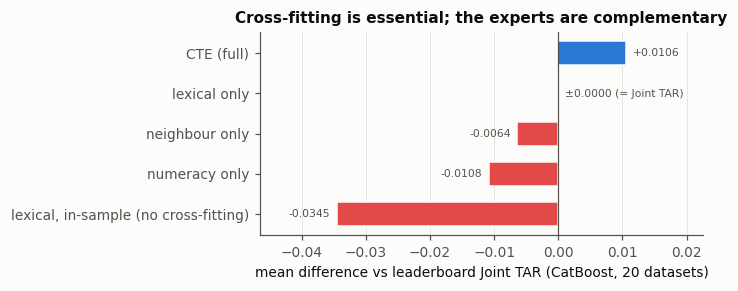

,variant,mean diff vs Joint TAR,mean diff vs full CTE
0,CTE (full),0.0106,0.0000
1,lexical only,-0.0000,-0.0106
2,neighbour only,-0.0064,-0.0170
3,numeracy only,-0.0108,-0.0214
4,"lexical, in-sample (no cross-fitting)",-0.0345,-0.0451


In [8]:
abl = {"CTE (full)": 0.0}
abl.update({k: v["vs_cte"]["mean_diff"] for k, v in c2["ablations"].items()})
names = {"CTE (full)": "CTE (full)", "cte_lex": "lexical only", "cte_nbr": "neighbour only", "cte_num": "numeracy only",
         "cte_lex_insample": "lexical, in-sample (no cross-fitting)"}
vs_ft = {"CTE (full)": c2["C2"]["mean_diff"]}
vs_ft.update({k: v["vs_leaderboard_ft"]["mean_diff"] for k, v in c2["ablations"].items()})
t = pd.DataFrame({"variant": [names[k] for k in vs_ft], "mean diff vs Joint TAR": [round(v, 4) for v in vs_ft.values()],
                  "mean diff vs full CTE": [round(abl[k], 4) for k in vs_ft]})
t.to_csv(R("tables", "table_ablations.csv"), index=False)
fig, ax = plt.subplots(figsize=(5.2, 2.4))
y = np.arange(len(t))[::-1]
v = t["mean diff vs Joint TAR"].values
ax.barh(y, v, color=[MID if abs(x) < 5e-4 else POS if x > 0 else NEG for x in v], height=0.6, edgecolor=SURFACE)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_yticks(y, t.variant); ax.grid(axis="y", visible=False)
for yi, x in zip(y, v):
    ax.text(x + (0.001 if x >= 0 else -0.001), yi, "±0.0000 (= Joint TAR)" if abs(x) < 5e-5 else f"{x:+.4f}", va="center",
            ha="left" if x >= 0 else "right", fontsize=7, color=INK2)
ax.set_xlim(v.min() - 0.012, v.max() + 0.012)
ax.set_xlabel("mean difference vs leaderboard Joint TAR (CatBoost, 20 datasets)")
ax.set_title("Cross-fitting is essential; the experts are complementary")
save(fig, "fig3_ablations"); plt.show()
t

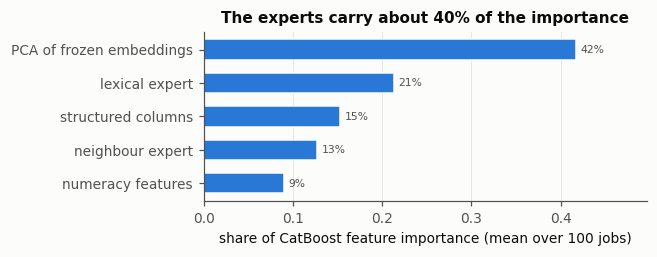

In [9]:
share = pd.Series(c2["group_share_catboost"]).rename({"pca": "PCA of frozen embeddings", "lex": "lexical expert",
                                                       "structured": "structured columns", "nbr": "neighbour expert",
                                                       "num": "numeracy features"}).sort_values()
fig, ax = plt.subplots(figsize=(5.2, 2.0))
ax.barh(np.arange(len(share)), share.values, color=BLUE, height=0.6, edgecolor=SURFACE)
ax.set_yticks(np.arange(len(share)), share.index); ax.grid(axis="y", visible=False)
for i, x in enumerate(share.values):
    ax.text(x + 0.005, i, f"{x:.0%}", va="center", fontsize=7, color=INK2)
ax.set_xlim(0, share.max() + 0.08); ax.set_xlabel("share of CatBoost feature importance (mean over 100 jobs)")
ax.set_title("The experts carry about 40% of the importance")
save(fig, "fig4_importance"); plt.show()

### 5.2 Where CTE loses: Jigsaw (E22, E24)

Jigsaw (toxic comment detection) is the one clear loss (−0.022, all 5 folds). It is also where fine-tuning helps
most on the leaderboard (TAR − Frozen: +0.108 with CatBoost, +0.117 averaged over the 5 learners). Whether a comment is toxic depends on meaning and context that bag-of-
words models miss; the lexical expert reaches an out-of-fold AUROC of only ≈ 0.86 there, while TAR reaches ≈ 0.93. This
is a real limitation of cheap experts, and the paper should say so.

In [10]:
j = cte[cte.dataset == "BIN_TEXT_JIGSAW_TOXICITY"][["fold", "score", "lb_joint_tar", "lb_joint_frozen", "lex_alpha"]]
j.rename(columns={"score": "CTE", "lb_joint_tar": "Joint TAR (LB)", "lb_joint_frozen": "Joint Frozen (LB)",
                  "lex_alpha": "chosen alpha"}).round(4)

,fold,CTE,Joint TAR (LB),Joint Frozen (LB),chosen alpha
34,0,0.8732,0.9137,0.7835,3.0
35,1,0.8966,0.9175,0.8069,3.0
36,2,0.9281,0.9289,0.8289,3.0
37,3,0.9094,0.9317,0.8235,3.0
38,4,0.9148,0.9420,0.8494,10.0


## 6. Compute (E6, E17, E24)

Careful wording matters here. Over the same 100 (dataset, fold) jobs, the **text step** of TAR (fine-tuning, with
our optimised engine, on a whole A100) took about as long as CTE's text step (frozen embeddings + experts, on CPU,
6 jobs sharing the machine). So we do **not** claim a measured 10× saving against our own TAR engine. What is true:
CTE needs **no gradient training and no GPU** beyond one frozen forward pass per unique text (cached per dataset and
shared by all folds and learners). Against TAR as implemented upstream (11.9× slower per epoch than our engine, E6,
one dataset on a T4), CTE is roughly an order of magnitude cheaper; that is an extrapolation and is labelled so.

In [11]:
tar = fold[(fold.method == "tar_repro") & (fold.learner == "catboost")]
tar_text = (tar.tar_train_seconds.fillna(0) + tar.tar_encode_seconds.fillna(0) + tar.tar_lower_cache_seconds.fillna(0)).sum() / 3600
cte_text = (cte.emb_seconds.fillna(0) + cte.expert_seconds.fillna(0)).sum() / 3600
comp = pd.DataFrame([
    {"step": "TAR fine-tuning + encoding (our engine)", "hardware": "1 job at a time, whole A100", "hours (100 jobs)": round(tar_text, 2),
     "source": "E17"},
    {"step": "CTE frozen embeddings + experts", "hardware": "6 jobs in parallel, 2 CPU threads each (A100 VM)", "hours (100 jobs)": round(cte_text, 2),
     "source": "E24"},
    {"step": "whole CatBoost jobs, TAR (tar_repro)", "hardware": "as above", "hours (100 jobs)": round(tar.job_seconds.sum() / 3600, 2), "source": "E17"},
    {"step": "whole CatBoost jobs, CTE", "hardware": "as above (CatBoost on 2 threads)", "hours (100 jobs)": round(cte.job_seconds.sum() / 3600, 2), "source": "E24"},
])
comp.to_csv(R("tables", "table_compute.csv"), index=False)
comp

,step,hardware,hours (100 jobs),source
0,TAR fine-tuning + encoding (our engine),"1 job at a time, whole A100",3.07,E17
1,CTE frozen embeddings + experts,"6 jobs in parallel, 2 CPU threads each (A100 VM)",2.76,E24
2,"whole CatBoost jobs, TAR (tar_repro)",as above,5.58,E17
3,"whole CatBoost jobs, CTE",as above (CatBoost on 2 threads),19.66,E24


## 7. P6 — Claim C3: two variants of CTE (pre-registered 2026-10-14, amended 2026-10-15)

Two CatBoost variants of CTE, each changing one thing:
- **`cte_nb`**: for classification, the lexical expert weights each TF-IDF feature by how much more often it appears in
  one class than in the others (naive-Bayes log-count ratio, NBSVM-style), then fits a Ridge per class. Regression is
  unchanged.
- **`cte_residual`**: the experts no longer learn the label. They learn **what a structured-only CatBoost gets wrong**
  (its residuals), so the text only has to explain what the table cannot. It is still cross-fitted, nested, so no
  row's label reaches its own prediction.

**Claim C3** (amendment 2): each vs leaderboard Joint TAR, Holm-corrected over the two; pass = adjusted p < 0.05 and a
positive mean. C3 never replaces C2. Two further variants that use CatBoost's own text features (`catboost_native_text`,
`cte_plus_native`) were **dropped for runtime** (Jigsaw ran 5 h 20 min without finishing a fold). Their 29 finished jobs
appear below only as a descriptive side table.

In [12]:
p6 = R("p6", "p6_report.json")
r6 = json.load(open(p6)) if exists(p6) else None
if r6 is None:
    display(Markdown("**P6 results not in the repo yet** — run `scripts/p6_report.py` on the export, then re-run this notebook."))
else:
    rows = []
    for k, lab_ in (("C3", "C3 — all 20 datasets"), ("C3_heldout13", "held-out 13 (secondary)")):
        for v, c in r6[k].items():
            rows.append({"set": lab_, "variant": v, "n": c["n"], "mean diff vs Joint TAR": round(c["mean_diff"], 4),
                         "95% CI": f"[{c['ci95'][0]:+.4f}, {c['ci95'][1]:+.4f}]", "p": fmt_p(c["p_value"]),
                         "p (Holm, 2 tests)": fmt_p(c["p_holm"]), "wins": c["wins"],
                         "passes": "PASS" if c["passes"] else "no"})
    for v, d in r6["all20"].items():
        c = d["vs_cte"]
        rows.append({"set": "exploratory: vs our CTE", "variant": v, "n": c["n"], "mean diff vs Joint TAR": None,
                     "95% CI": f"[{c['ci95'][0]:+.4f}, {c['ci95'][1]:+.4f}]", "p": fmt_p(c["p_value"]),
                     "p (Holm, 2 tests)": "—", "wins": c["wins"], "passes": f"mean vs CTE {c['mean_diff']:+.4f}"})
    table_c3 = pd.DataFrame(rows)
    table_c3.to_csv(R("tables", "table_c3.csv"), index=False)
    display(table_c3)

,set,variant,n,mean diff vs Joint TAR,95% CI,p,"p (Holm, 2 tests)",wins,passes
0,C3 — all 20 datasets,cte_nb,20,0.0112,"[+0.0038, +0.0196]",0.0484,0.0969,11,no
1,C3 — all 20 datasets,cte_residual,20,0.0102,"[+0.0023, +0.0189]",0.0637,0.0969,12,no
2,held-out 13 (secondary),cte_nb,13,0.0173,"[+0.0074, +0.0281]",0.0105,0.021,9,PASS
3,held-out 13 (secondary),cte_residual,13,0.0153,"[+0.0050, +0.0267]",0.0479,0.0479,9,PASS
4,exploratory: vs our CTE,cte_nb,20,NaN,"[-0.0001, +0.0016]",0.534,—,5,mean vs CTE +0.0005
5,exploratory: vs our CTE,cte_residual,20,NaN,"[-0.0030, +0.0035]",0.024,—,5,mean vs CTE -0.0004


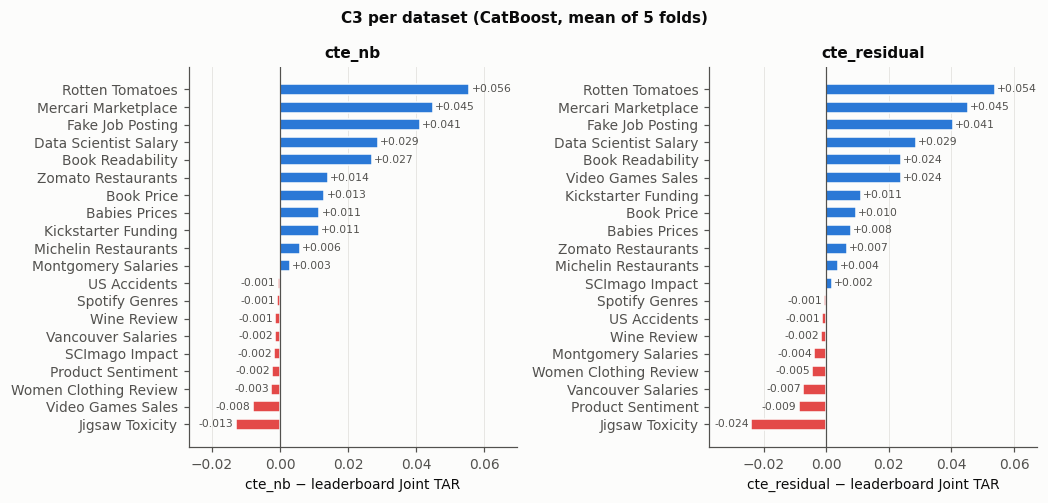

In [13]:
if r6 is not None:
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6), sharey=False)
    for ax, v in zip(axes, ("cte_nb", "cte_residual")):
        d = pd.Series(r6["C3"][v]["per_dataset"])
        diverging_bars(ax, [short(k) for k in d.index], list(d.values), xlabel=f"{v} − leaderboard Joint TAR")
        ax.set_title(v)
    fig.suptitle("C3 per dataset (CatBoost, mean of 5 folds)", fontweight="bold", fontsize=10)
    fig.tight_layout()
    save(fig, "fig5_c3_per_dataset"); plt.show()

In [14]:
if r6 is not None:
    nat = pd.DataFrame(r6["native_text_partial"])
    if len(nat):
        side = (nat.assign(diff=nat.score - nat.lb_joint_tar, calcers=nat.feature_calcers.map(lambda c: "+".join(c or [])))
                   .groupby("dataset").agg(folds=("fold", "count"), score=("score", "mean"), joint_tar=("lb_joint_tar", "mean"),
                                           diff=("diff", "mean"), calcers=("calcers", "first")).round(4))
        side.index = side.index.map(short)
        side.to_csv(R("tables", "table_native_text_partial.csv"))
        display(Markdown(f"**catboost_native_text — dropped, partial ({len(nat)} finished jobs), descriptive only; no test, no claim.**"))
        display(side)

**catboost_native_text — dropped, partial (29 finished jobs), descriptive only; no test, no claim.**

,folds,score,joint_tar,diff,calcers
dataset,,,,,
Product Sentiment,5,0.8887,0.9138,-0.0250,BoW+NaiveBayes+BM25
Wine Review,5,0.9721,0.9815,-0.0094,BoW
Women Clothing Review,4,0.8775,0.9096,-0.0321,BoW+NaiveBayes+BM25
Babies Prices,5,0.8984,0.8931,0.0052,BoW
Vancouver Salaries,5,0.7344,0.7877,-0.0534,BoW
Video Games Sales,5,0.0087,0.4187,-0.4100,BoW


## 8. P8 — Claims C4 and C5: both pass (pre-registered 2026-10-16)

A development round (P7) on dev splits of the **training rows** of 6 datasets (test rows never used) picked two
additions, which were then pre-registered and run once on all 20 datasets × 5 folds:

- **`tf_num_lsa` (label-free)**: frozen PCA + numeracy features + 30 LSA components (TF-IDF → SVD) of the text. No label is
  used to build the text features, so the course criterion is to beat **Joint Frozen**. → **claim C4**.
- **`cte_probe` (label-aware)**: CTE + a cross-fitted **linear probe** on the full 384-d frozen embeddings (PCA-30 keeps
  variance, not target signal; the probe hands the learner an out-of-fold E[y | embedding]). It must beat **Joint TAR**.
  → **claim C5**.

Holm correction over the two claims. An **environment control** (our own Joint Frozen, `frozen0`) checks that our setup
does not score higher than the leaderboard's by itself.

In [15]:
r8 = json.load(open(R("p8", "p8_report.json"))) if exists(R("p8", "p8_report.json")) else None
if r8 is None:
    display(Markdown("**P8 results not in the repo yet.**"))
else:
    lab8 = {"C4": "C4 — tf_num_lsa vs Joint Frozen (label-free claim)", "C5": "C5 — cte_probe vs Joint TAR (label-aware claim)",
            "C5_heldout13": "C5 on the held-out 13 (secondary)", "C5_vs_our_cte": "cte_probe vs our CTE (secondary)",
            "C4_env_control_vs_our_frozen0": "tf_num_lsa vs our own Joint Frozen (environment control, 19)",
            "env_frozen0_vs_leaderboard_frozen": "our Joint Frozen vs leaderboard Joint Frozen (environment, 19)",
            "C4_descriptive_vs_joint_tar": "tf_num_lsa vs Joint TAR (descriptive)"}
    rows = [{"comparison": name, "n": r8[k]["n"], "mean diff": round(r8[k]["mean_diff"], 4),
             "95% CI": f"[{r8[k]['ci95'][0]:+.4f}, {r8[k]['ci95'][1]:+.4f}]", "p": fmt_p(r8[k]["p_value"]),
             "p (Holm)": fmt_p(r8[k].get("p_holm")) if k in ("C4", "C5") else "—", "wins": r8[k]["wins"],
             "passes": ("PASS" if r8[k]["passes"] else "no") if k in ("C4", "C5") else "—"} for k, name in lab8.items()]
    table_p8 = pd.DataFrame(rows)
    table_p8.to_csv(R("tables", "table_p8.csv"), index=False)
    display(table_p8)

,comparison,n,mean diff,95% CI,p,p (Holm),wins,passes
0,C4 — tf_num_lsa vs Joint Frozen (label-free cl...,20,0.0129,"[+0.0060, +0.0218]",1.9e-05,3.8e-05,18,PASS
1,C5 — cte_probe vs Joint TAR (label-aware claim),20,0.0141,"[+0.0066, +0.0222]",0.00233,0.00233,15,PASS
2,C5 on the held-out 13 (secondary),13,0.0184,"[+0.0083, +0.0294]",0.00464,—,10,—
3,cte_probe vs our CTE (secondary),20,0.0035,"[+0.0013, +0.0063]",7.1e-04,—,17,—
4,tf_num_lsa vs our own Joint Frozen (environmen...,19,0.0119,"[+0.0064, +0.0187]",3.8e-05,—,17,—
5,our Joint Frozen vs leaderboard Joint Frozen (...,19,0.0015,"[-0.0011, +0.0059]",0.465,—,9,—
6,tf_num_lsa vs Joint TAR (descriptive),20,-0.0076,"[-0.0205, +0.0019]",0.0328,—,5,—


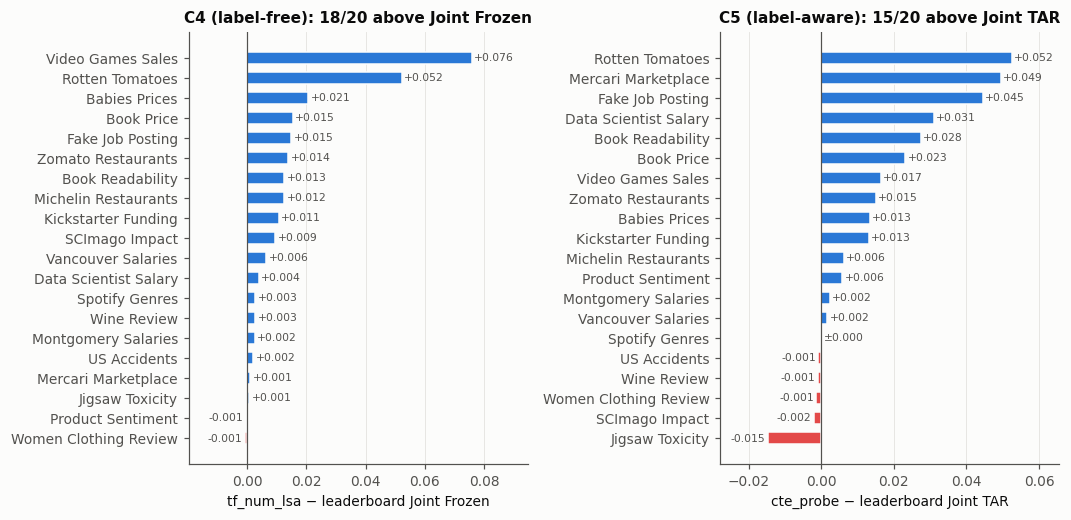

In [16]:
if r8 is not None:
    fig, axes = plt.subplots(1, 2, figsize=(9.8, 4.8))
    for ax, k, xl, title in ((axes[0], "C4", "tf_num_lsa − leaderboard Joint Frozen", "C4 (label-free): 18/20 above Joint Frozen"),
                              (axes[1], "C5", "cte_probe − leaderboard Joint TAR", "C5 (label-aware): 15/20 above Joint TAR")):
        d = pd.Series(r8[k]["per_dataset"])
        diverging_bars(ax, [short(i) for i in d.index], list(d.values), xlabel=xl)
        ax.set_title(title)
    fig.tight_layout()
    save(fig, "fig6_c4_c5_per_dataset"); plt.show()

**Reading the results.** Both claims pass. The label-free features alone beat Joint Frozen on 18 of 20 datasets
(p = 2e-5), and the environment control shows that our setup and the leaderboard's agree on Joint Frozen (+0.0015,
p = 0.47), so the gain is the method's. The probe lifts CTE by a small but consistent +0.0035 (17/20) and turns the
narrow C2 miss (p = 0.058) into a clear pass for `cte_probe` vs Joint TAR (+0.0141, 15/20, p = 0.0023). One caveat:
on Video Games our own Joint Frozen is +0.039 above the leaderboard's. Post-hoc checks without that dataset, or after
subtracting each dataset's environment offset, keep both claims significant (PROGRESS.md E28, E29).

## 9. Summary for the paper

- **Final method, CTE + probe (`cte_probe`, label-aware)** — **C5 passes**: +0.0141 vs Joint TAR, 15/20 datasets,
  p = 0.0023 (Holm), no fine-tuning. Held-out 13: +0.0184 (p = 0.0046).
- **Label-free variant (`tf_num_lsa`)** — **C4 passes**: +0.0129 vs Joint Frozen, 18/20, p = 2e-5 (Holm 4e-5).
- **Earlier claims, reported as pre-registered** — C1 (P4) does not pass. C2 (plain CTE, p = 0.058) narrowly does
  not pass on all 20. C3 (NB / residual variants) does not pass.
- **Mechanism** — cross-fitting is essential (in-sample lexical: −0.045 vs CTE). Lexical, neighbour, numeracy and
  probe experts are complementary.
- **Limitation** — Jigsaw (toxicity) is still below TAR (−0.015), where fine-tuning helps most.
- **Compute** — no fine-tuning and no GPU training. Comparable text-step time to our optimised TAR engine, roughly
  an order of magnitude below TAR as implemented upstream (extrapolated from E6).

Figures are saved to `reports/figures/` (PDF for the paper, PNG for slides) and tables to `reports/tables/`.